# ML Assignment 2 Q2: Multiclass Boosting from Scratch
**Amrit Kumar Giri (M26ECC001)**

## Imports and saved Q1 split

In [1]:
from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

SEED = 26001
DATA_DIR = Path('data')
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)

split_file = DATA_DIR / 'saved_split.npz'
if not split_file.exists():
    raise FileNotFoundError('Put this notebook in the SAME folder as Q1, with data/saved_split.npz present.')

faces = fetch_olivetti_faces(shuffle=False)
X, y = faces.data, faces.target
saved = np.load(split_file)
train_idx, val_idx, test_idx = [saved[name] for name in ('train_idx', 'val_idx', 'test_idx')]
assert int(saved['seed']) == SEED
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
K = len(np.unique(y_train))
assert X_train.shape == (240, 4096) and X_val.shape == (80, 4096) and X_test.shape == (80, 4096)
assert K == 40
print('Train:', X_train.shape, '| Validation:', X_val.shape, '| Test:', X_test.shape)
print('Classes:', K, '| Random seed:', SEED)

Train: (240, 4096) | Validation: (80, 4096) | Test: (80, 4096)
Classes: 40 | Random seed: 26001


## Q2(a): SAMME

In [2]:
toy_true = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
toy_pred = np.array([0, 0, 1, 1, 1, 2, 2, 2, 0])
toy_weights = np.full(len(toy_true), 1 / len(toy_true))

toy_wrong = toy_pred != toy_true
toy_error = toy_weights[toy_wrong].sum()
toy_alpha = np.log((1 - toy_error) / toy_error) + np.log(3 - 1)
toy_updated = toy_weights * np.exp(toy_alpha * toy_wrong)
toy_updated /= toy_updated.sum()

toy_log = pd.DataFrame({
    'true_class': toy_true,
    'prediction': toy_pred,
    'wrong': toy_wrong,
    'old_weight': toy_weights,
    'new_weight': toy_updated
})
print(f'Weighted error = {toy_error:.6f}')
print(f'Alpha = {toy_alpha:.6f}')
print(f'Updated weights sum = {toy_updated.sum():.6f}')
display(toy_log.round(6))
assert np.isclose(toy_updated.sum(), 1)
assert toy_updated[toy_wrong].mean() > toy_updated[~toy_wrong].mean()

Weighted error = 0.333333
Alpha = 1.386294
Updated weights sum = 1.000000


,true_class,prediction,wrong,old_weight,new_weight
0,0,0,False,0.111111,0.055556
1,0,0,False,0.111111,0.055556
2,0,1,True,0.111111,0.222222
3,1,1,False,0.111111,0.055556
4,1,1,False,0.111111,0.055556
5,1,2,True,0.111111,0.222222
6,2,2,False,0.111111,0.055556
7,2,2,False,0.111111,0.055556
8,2,0,True,0.111111,0.222222


## SAMME implemented from scratch

In [12]:
class MySAMME:
    def __init__(self, max_depth=1, n_rounds=50, random_state=26001):
        self.max_depth = max_depth
        self.n_rounds = n_rounds
        self.random_state = random_state

    def fit(self, X_data, labels, watch_index=None):
        self.classes_ = np.unique(labels)
        self.n_classes_ = len(self.classes_)
        n = len(labels)
        weights = np.full(n, 1.0 / n)
        self.trees_ = []
        self.alphas_ = []
        self.history_ = []
        self.watch_history_ = []
        self.weight_snapshots_ = []
        random = np.random.default_rng(self.random_state)

        for round_id in range(self.n_rounds):
            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=int(random.integers(0, 2**31 - 1))
            )
            tree.fit(X_data, labels, sample_weight=weights)
            predictions = tree.predict(X_data)
            wrong = predictions != labels
            error = float(weights[wrong].sum())
            random_error = 1.0 - 1.0 / self.n_classes_

            if error <= 1e-15:
                alpha = np.log((1 - 1e-15) / 1e-15) + np.log(self.n_classes_ - 1)
                self.trees_.append(tree)
                self.alphas_.append(float(alpha))
                self.history_.append({'round': round_id + 1, 'weighted_error': 0.0,
                                      'alpha': float(alpha), 'max_weight': float(weights.max()),
                                      'train_accuracy': 1.0})
                self.weight_snapshots_.append(weights.copy())
                if watch_index is not None:
                    self.watch_history_.append({'round': round_id + 1, 'sample_weight': float(weights[watch_index]),
                                                'learner_correct': bool(not wrong[watch_index])})
                break

            if not np.isfinite(error) or error >= random_error:
                print(f'Stopped at round {round_id + 1}: weak learner error {error:.4f} '
                      f'is not below {random_error:.4f}.')
                break

            alpha = float(np.log((1 - error) / error) + np.log(self.n_classes_ - 1))
            weights *= np.exp(alpha * wrong)
            weights /= weights.sum()

            self.trees_.append(tree)
            self.alphas_.append(alpha)
            self.weight_snapshots_.append(weights.copy())
            self.history_.append({'round': round_id + 1, 'weighted_error': error,
                                  'alpha': alpha, 'max_weight': float(weights.max()),
                                  'train_accuracy': float(np.mean(predictions == labels))})
            if watch_index is not None:
                self.watch_history_.append({'round': round_id + 1, 'sample_weight': float(weights[watch_index]),
                                            'learner_correct': bool(not wrong[watch_index])})

        if not self.trees_:
            raise RuntimeError('No valid weak learner was fitted. Try a different depth.')
        self.alphas_ = np.asarray(self.alphas_, dtype=float)
        return self

    def scores(self, X_data, n_rounds=None):
        count = len(self.trees_) if n_rounds is None else min(n_rounds, len(self.trees_))
        score = np.zeros((len(X_data), self.n_classes_), dtype=float)
        class_lookup = {value: idx for idx, value in enumerate(self.classes_)}
        rows = np.arange(len(X_data))
        for tree, alpha in zip(self.trees_[:count], self.alphas_[:count]):
            pred = tree.predict(X_data)
            columns = np.array([class_lookup[value] for value in pred])
            score[rows, columns] += alpha
        return score

    def predict(self, X_data, n_rounds=None):
        return self.classes_[self.scores(X_data, n_rounds).argmax(axis=1)]

    def vote_confidence(self, X_data, n_rounds=None):
        scores = self.scores(X_data, n_rounds)
        totals = scores.sum(axis=1)
        return scores.max(axis=1) / totals

    def margins(self, X_data, n_rounds=None):
        scores = self.scores(X_data, n_rounds)
        ordered = np.sort(scores, axis=1)
        return (ordered[:, -1] - ordered[:, -2]) / scores.sum(axis=1)

In [4]:
small_check = MySAMME(max_depth=1, n_rounds=3, random_state=SEED).fit(X_train, y_train)
print('Learners fitted:', len(small_check.trees_))
print('Predictions for first five validation faces:', small_check.predict(X_val[:5]))
print('Average normalized winning score:', round(small_check.vote_confidence(X_val).mean(), 4))
assert small_check.scores(X_val).shape == (80, K)
assert np.all(small_check.alphas_ > 0)

Learners fitted: 3
Predictions for first five validation faces: [2 2 2 2 2]
Average normalized winning score: 0.346


## Q2(b): Compare depths and number of rounds

In [5]:
depth_options = [1, 2, 3, 4]
round_options = [10, 25, 50, 100]
boost_models = {}
boost_rows = []

for depth in depth_options:
    print(f'Training depth {depth} ...')
    start = time.perf_counter()
    model = MySAMME(max_depth=depth, n_rounds=100, random_state=SEED + depth)
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    boost_models[depth] = model
    fitted = len(model.trees_)

    for rounds in round_options:
        used = min(rounds, fitted)
        boost_rows.append({
            'depth': depth,
            'requested_rounds': rounds,
            'actual_rounds': used,
            'train_acc': accuracy_score(y_train, model.predict(X_train, used)),
            'val_acc': accuracy_score(y_val, model.predict(X_val, used)),
            'training_error': 1 - accuracy_score(y_train, model.predict(X_train, used)),
            'elapsed_depth_total_s': elapsed,
        })
    print(f'  Learners fitted: {fitted} | total time: {elapsed:.2f} s')

boost_results = pd.DataFrame(boost_rows)
display(boost_results.round(4))
boost_results.to_csv(RESULT_DIR / 'q2b_boosting_grid.csv', index=False)

Training depth 1 ...
  Learners fitted: 100 | total time: 15.39 s
Training depth 2 ...
  Learners fitted: 100 | total time: 28.97 s
Training depth 3 ...
  Learners fitted: 100 | total time: 43.75 s
Training depth 4 ...
  Learners fitted: 100 | total time: 57.71 s


,depth,requested_rounds,actual_rounds,train_acc,val_acc,training_error,elapsed_depth_total_s
0,1,10,10,0.0500,0.0500,0.9500,15.3891
1,1,25,25,0.0917,0.0875,0.9083,15.3891
2,1,50,50,0.1750,0.1000,0.8250,15.3891
3,1,100,100,0.1667,0.1250,0.8333,15.3891
4,2,10,10,0.0958,0.0750,0.9042,28.9701
5,2,25,25,0.1708,0.1125,0.8292,28.9701
6,2,50,50,0.2625,0.1750,0.7375,28.9701
7,2,100,100,0.5458,0.2250,0.4542,28.9701
8,3,10,10,0.2958,0.1750,0.7042,43.7545
9,3,25,25,0.5042,0.3250,0.4958,43.7545


### Plots: accuracy and training error

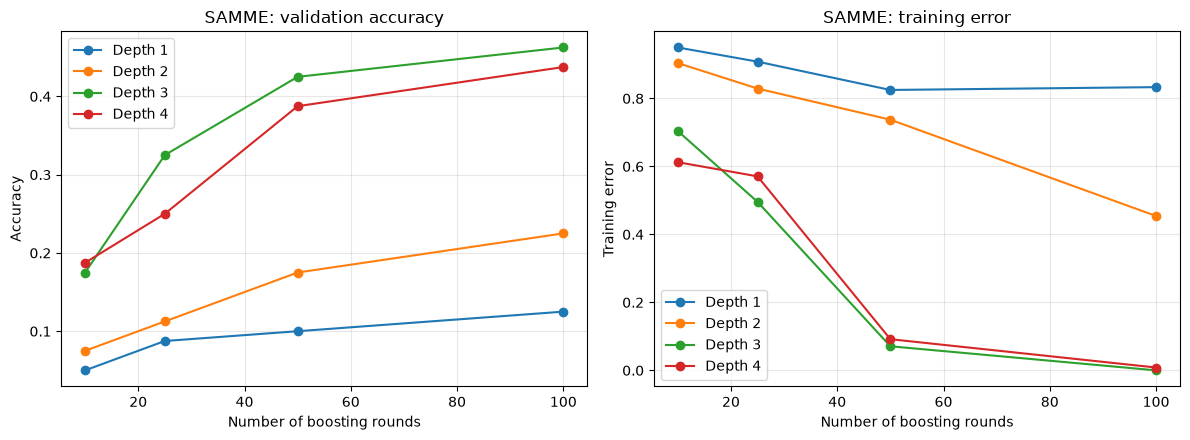

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for depth in depth_options:
    piece = boost_results[boost_results['depth'] == depth]
    axes[0].plot(piece.requested_rounds, piece.val_acc, marker='o', label=f'Depth {depth}')
    axes[1].plot(piece.requested_rounds, piece.training_error, marker='o', label=f'Depth {depth}')
axes[0].set_title('SAMME: validation accuracy')
axes[1].set_title('SAMME: training error')
for ax in axes:
    ax.set_xlabel('Number of boosting rounds')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel('Accuracy')
axes[1].set_ylabel('Training error')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q2b_accuracy_error.png', dpi=300)
plt.show()

### Boosting configuration

In [13]:
ranked_boost = boost_results.sort_values(
    ['val_acc', 'requested_rounds', 'depth'],
    ascending=[False, True, True], kind='stable'
)
best = ranked_boost.iloc[0]
BEST_DEPTH = int(best.depth)
BEST_ROUNDS = int(best.actual_rounds)
final_boost = boost_models[BEST_DEPTH]
print('Selected depth:', BEST_DEPTH)
print('Selected boosting rounds:', BEST_ROUNDS)
print('Validation accuracy:', round(float(best.val_acc), 4))
print('Clean test accuracy:', round(accuracy_score(y_test, final_boost.predict(X_test, BEST_ROUNDS)), 4))

boost_results['clean_test_acc'] = [
    accuracy_score(y_test, boost_models[int(row.depth)].predict(
        X_test, int(row.actual_rounds)))
    for row in boost_results.itertuples(index=False)
]
boost_results.to_csv(RESULT_DIR / 'q2b_boosting_grid.csv', index=False)
with open(RESULT_DIR / 'q2_selected_config.json', 'w') as file:
    json.dump({'max_depth': BEST_DEPTH, 'n_rounds': BEST_ROUNDS,
               'seed': SEED, 'validation_accuracy': float(best.val_acc)}, file, indent=2)
display(boost_results.round(4))

Selected depth: 3
Selected boosting rounds: 100
Validation accuracy: 0.4625
Clean test accuracy: 0.5


,depth,requested_rounds,actual_rounds,train_acc,val_acc,training_error,elapsed_depth_total_s,clean_test_acc
0,1,10,10,0.0500,0.0500,0.9500,15.3891,0.0375
1,1,25,25,0.0917,0.0875,0.9083,15.3891,0.0500
2,1,50,50,0.1750,0.1000,0.8250,15.3891,0.1125
3,1,100,100,0.1667,0.1250,0.8333,15.3891,0.0625
4,2,10,10,0.0958,0.0750,0.9042,28.9701,0.0750
5,2,25,25,0.1708,0.1125,0.8292,28.9701,0.1125
6,2,50,50,0.2625,0.1750,0.7375,28.9701,0.1625
7,2,100,100,0.5458,0.2250,0.4542,28.9701,0.2750
8,3,10,10,0.2958,0.1750,0.7042,43.7545,0.1625
9,3,25,25,0.5042,0.3250,0.4958,43.7545,0.3000


### Learner weights and maximum sample weights

,round,weighted_error,alpha,max_weight
0,1,0.87500,1.71765,0.00464
1,2,0.88857,1.58733,0.00509
2,3,0.87773,1.69243,0.00566
3,4,0.86418,1.81308,0.00638
4,5,0.84260,1.98585,0.00739
...,...,...,...,...
95,96,0.69312,2.84882,0.06158
96,97,0.75026,2.56354,0.03097
97,98,0.72047,2.71675,0.04191
98,99,0.74482,2.59238,0.02959


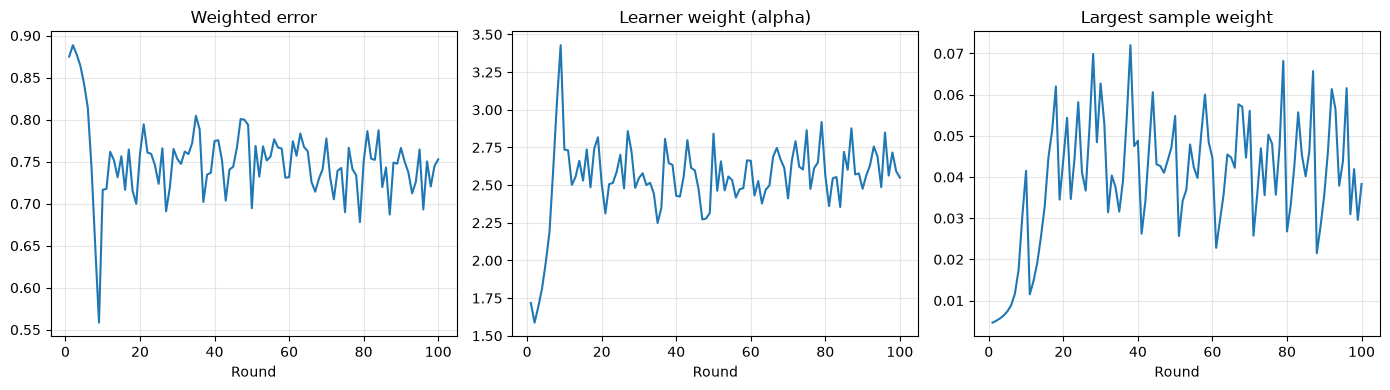

In [8]:
history_df = pd.DataFrame(final_boost.history_[:BEST_ROUNDS])
display(history_df[['round', 'weighted_error', 'alpha', 'max_weight']].round(5))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column, label in zip(axes,
    ['weighted_error', 'alpha', 'max_weight'],
    ['Weighted error', 'Learner weight (alpha)', 'Largest sample weight']):
    ax.plot(history_df['round'], history_df[column])
    ax.set_title(label)
    ax.set_xlabel('Round')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q2b_round_diagnostics.png', dpi=300)
plt.show()

## Q2(c): Compare boosting with bagging learners

In [9]:
from joblib import Parallel, delayed

q1_file = RESULT_DIR / 'q1a_tree_configs.csv'
if not q1_file.exists():
    raise FileNotFoundError('First run Q1 in the same project to create results/q1a_tree_configs.csv')
q1_table = pd.read_csv(q1_file)
q1_best = q1_table.sort_values(['val_acc', 'n_leaves', 'min_leaf'],
                               ascending=[False, True, False]).iloc[0]
q1_depth = None if pd.isna(q1_best.depth) else int(q1_best.depth)
q1_leaf = int(q1_best.min_leaf)

boot_rng = np.random.default_rng(SEED + 1)
boot_indices = [boot_rng.integers(0, len(X_train), len(X_train)) for _ in range(100)]
boot_seeds = np.random.default_rng(SEED + 2).integers(0, 2**31 - 1, size=100)

def fit_bag_tree(i):
    tree = DecisionTreeClassifier(max_depth=q1_depth,
        min_samples_leaf=q1_leaf, random_state=int(boot_seeds[i]))
    tree.fit(X_train[boot_indices[i]], y_train[boot_indices[i]])
    return tree

q1_bag_models = []
bag_time = {}
start = time.perf_counter()
for i in range(100):
    q1_bag_models.append(fit_bag_tree(i))
    if i + 1 in [25, 50, 100]:
        bag_time[i + 1] = time.perf_counter() - start

print('Bagging checkpoint times:', {b: round(t, 2) for b, t in bag_time.items()})

Bagging checkpoint times: {25: 48.64, 50: 94.14, 100: 184.03}


,method,learners,train_acc,val_acc,test_acc,train_time_s
0,Bagging,25,1.0000,0.9250,0.7500,48.6408
1,Bagging,50,0.9958,0.9375,0.8000,94.1394
2,Bagging,100,0.9958,0.9250,0.7875,184.0326
3,Boosting,25,0.5042,0.3250,0.3000,10.9448
4,Boosting,50,0.9292,0.4250,0.4250,22.4547
5,Boosting,100,1.0000,0.4625,0.5000,44.4311


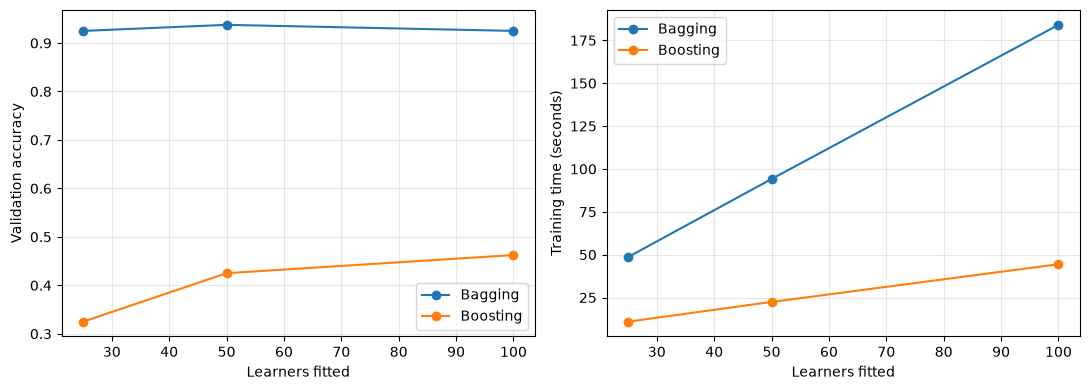

In [11]:
def bag_votes(trees, images):
    labels = np.zeros((len(images), K), dtype=int)
    for tree in trees:
        predictions = tree.predict(images).astype(int)
        labels[np.arange(len(images)), predictions] += 1
    return labels

def bag_predict(trees, images):
    return bag_votes(trees, images).argmax(axis=1)

comparison_rows = []
for B in [25, 50, 100]:
    trees = q1_bag_models[:B]
    for name, acc_train, acc_val, acc_test, elapsed in [
        ('Bagging', accuracy_score(y_train, bag_predict(trees, X_train)),
         accuracy_score(y_val, bag_predict(trees, X_val)),
         accuracy_score(y_test, bag_predict(trees, X_test)), bag_time[B]),
    ]:
        comparison_rows.append({'method': name, 'learners': B,
                                'train_acc': acc_train, 'val_acc': acc_val,
                                'test_acc': acc_test, 'train_time_s': elapsed})

for B in [25, 50, 100]:
    start = time.perf_counter()
    boosted = MySAMME(max_depth=BEST_DEPTH, n_rounds=B,
                       random_state=SEED + BEST_DEPTH).fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    comparison_rows.append({'method': 'Boosting', 'learners': len(boosted.trees_),
        'train_acc': accuracy_score(y_train, boosted.predict(X_train)),
        'val_acc': accuracy_score(y_val, boosted.predict(X_val)),
        'test_acc': accuracy_score(y_test, boosted.predict(X_test)),
        'train_time_s': elapsed})

q2c_table = pd.DataFrame(comparison_rows)
display(q2c_table.round(4))
q2c_table.to_csv(RESULT_DIR / 'q2c_bagging_vs_boosting.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method, subset in q2c_table.groupby('method'):
    axes[0].plot(subset.learners, subset.val_acc, marker='o', label=method)
    axes[1].plot(subset.learners, subset.train_time_s, marker='o', label=method)
axes[0].set_ylabel('Validation accuracy')
axes[1].set_ylabel('Training time (seconds)')
for ax in axes:
    ax.set_xlabel('Learners fitted')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q2c_comparison.png', dpi=300)
plt.show()

### Inspect an image that boosting pays unusually high attention

Training image index: 200
True identity: 33
Maximum weight: 0.07201 | at round 38


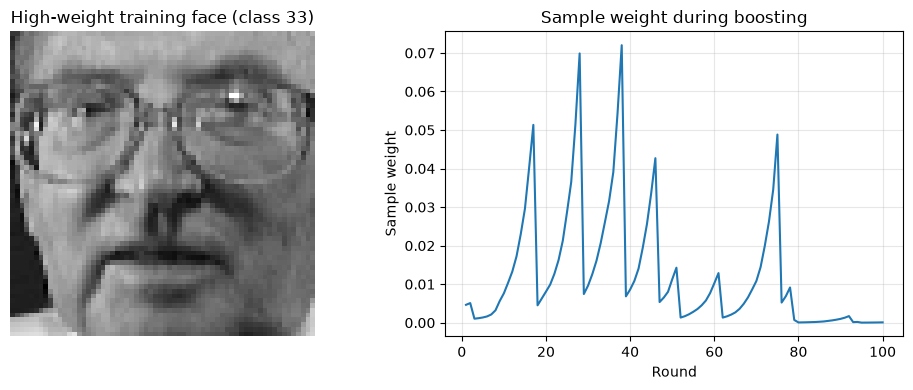

First prediction: 0 | Last prediction: 33
Was the final prediction correct? True
Number of prediction changes: 15


In [14]:
weights = np.stack(final_boost.weight_snapshots_[:BEST_ROUNDS])
round_pos, hard_idx = np.unravel_index(np.argmax(weights), weights.shape)
print('Training image index:', hard_idx)
print('True identity:', int(y_train[hard_idx]))
print('Maximum weight:', round(float(weights[round_pos, hard_idx]), 5),
      '| at round', round_pos + 1)

hard_weight_history = weights[:, hard_idx]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(X_train[hard_idx].reshape(64, 64), cmap='gray')
axes[0].set_title(f'High-weight training face (class {y_train[hard_idx]})')
axes[0].axis('off')
axes[1].plot(np.arange(1, BEST_ROUNDS + 1), hard_weight_history)
axes[1].set_title('Sample weight during boosting')
axes[1].set_xlabel('Round')
axes[1].set_ylabel('Sample weight')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q2c_high_weight_face.png', dpi=300)
plt.show()

pred_history = []
for t in range(1, BEST_ROUNDS + 1):
    pred_history.append(int(final_boost.predict(X_train[hard_idx:hard_idx + 1], t)[0]))
print('First prediction:', pred_history[0], '| Last prediction:', pred_history[-1])
print('Was the final prediction correct?', pred_history[-1] == y_train[hard_idx])
print('Number of prediction changes:', sum(a != b for a, b in zip(pred_history[:-1], pred_history[1:])))

## Q2(d): Final clean-versus-masked test comparison

In [15]:
def mask_centre(images):
    batch = images.reshape(-1, 64, 64).copy()
    batch[:, 24:40, 24:40] = 0
    return batch.reshape(-1, 4096)

X_test_masked = mask_centre(X_test)
assert np.all(X_test_masked.reshape(-1, 64, 64)[:, 24:40, 24:40] == 0)

q1_tree = DecisionTreeClassifier(max_depth=q1_depth, min_samples_leaf=q1_leaf,
                                 random_state=SEED).fit(X_train, y_train)
q1_bag_csv = pd.read_csv(RESULT_DIR / 'q1b_bagging_accuracy.csv')
BEST_B = int(q1_bag_csv.sort_values(['val_acc', 'B'],
                                   ascending=[False, True]).iloc[0].B)
q1_bag_final = q1_bag_models[:BEST_B]

def tree_confidence(tree, images):
    return tree.predict_proba(images).max(axis=1)

def bag_confidence(trees, images):
    return bag_votes(trees, images).max(axis=1) / len(trees)

models_to_compare = [
    ('Single Tree', q1_tree.predict, lambda img: tree_confidence(q1_tree, img)),
    ('Bagging', lambda img: bag_predict(q1_bag_final, img),
     lambda img: bag_confidence(q1_bag_final, img)),
    ('Boosting', lambda img: final_boost.predict(img, BEST_ROUNDS),
     lambda img: final_boost.vote_confidence(img, BEST_ROUNDS))
]

final_rows = []
for name, predict_fn, confidence_fn in models_to_compare:
    clean_pred = predict_fn(X_test)
    masked_pred = predict_fn(X_test_masked)
    final_rows.append({
        'model': name,
        'clean_accuracy': accuracy_score(y_test, clean_pred),
        'masked_accuracy': accuracy_score(y_test, masked_pred),
        'clean_confidence': confidence_fn(X_test).mean(),
        'masked_confidence': confidence_fn(X_test_masked).mean(),
    })

final_q2 = pd.DataFrame(final_rows)
final_q2['accuracy_drop_pp'] = 100 * (final_q2.clean_accuracy - final_q2.masked_accuracy)
display(final_q2.round(4))
final_q2.to_csv(RESULT_DIR / 'q2d_final_comparison.csv', index=False)

,model,clean_accuracy,masked_accuracy,clean_confidence,masked_confidence,accuracy_drop_pp
0,Single Tree,0.5375,0.3500,0.9670,0.9982,18.75
1,Bagging,0.8000,0.6125,0.3672,0.2660,18.75
2,Boosting,0.5000,0.4625,0.0954,0.0910,3.75


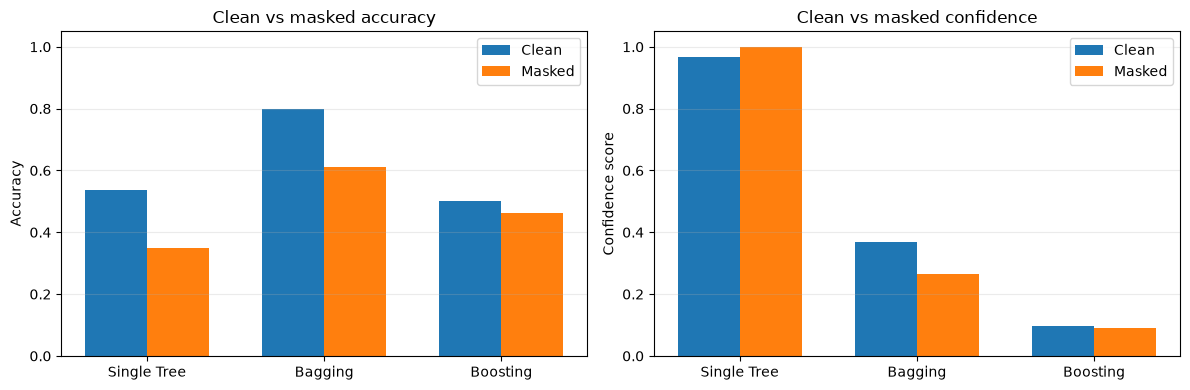

Bagging mean margin, clean: 0.2332
Bagging mean margin, masked: 0.1372
Boosting mean margin, clean: 0.013
Boosting mean margin, masked: 0.0138


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.arange(len(final_q2))
width = 0.35
for ax, first, second, ylabel, heading in [
    (axes[0], 'clean_accuracy', 'masked_accuracy', 'Accuracy', 'Clean vs masked accuracy'),
    (axes[1], 'clean_confidence', 'masked_confidence', 'Confidence score', 'Clean vs masked confidence')
]:
    ax.bar(xx - width / 2, final_q2[first], width, label='Clean')
    ax.bar(xx + width / 2, final_q2[second], width, label='Masked')
    ax.set_xticks(xx, final_q2.model)
    ax.set_ylabel(ylabel)
    ax.set_title(heading)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q2d_final_comparison.png', dpi=300)
plt.show()

def bag_margin(trees, images):
    v = np.sort(bag_votes(trees, images), axis=1)
    return (v[:, -1] - v[:, -2]) / len(trees)

print('Bagging mean margin, clean:', round(bag_margin(q1_bag_final, X_test).mean(), 4))
print('Bagging mean margin, masked:', round(bag_margin(q1_bag_final, X_test_masked).mean(), 4))
print('Boosting mean margin, clean:', round(final_boost.margins(X_test, BEST_ROUNDS).mean(), 4))
print('Boosting mean margin, masked:', round(final_boost.margins(X_test_masked, BEST_ROUNDS).mean(), 4))

### Compare two samples where bagging and boosting respond differently

Number of available contrasting examples: 26


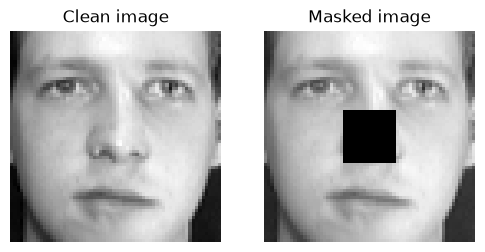

Test index 1 | true class 0
Bagging clean/masked: 0 / 0
Boosting clean/masked: 39 / 39
Top bag votes: [(0, np.int64(10)), (16, np.int64(9)), (13, np.int64(5))]
Top boosting alpha scores: [(39, 19.568), (12, 18.483), (20, 17.527)]


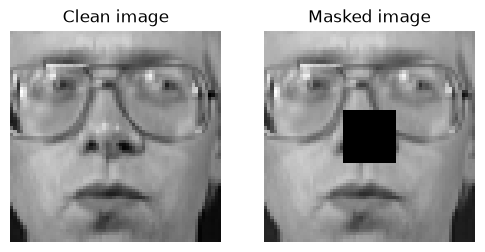

Test index 2 | true class 1
Bagging clean/masked: 1 / 1
Boosting clean/masked: 39 / 3
Top bag votes: [(1, np.int64(10)), (3, np.int64(5)), (13, np.int64(5))]
Top boosting alpha scores: [(3, 19.665), (39, 19.568), (12, 18.483)]


In [17]:
bag_clean = bag_predict(q1_bag_final, X_test)
bag_masked = bag_predict(q1_bag_final, X_test_masked)
boost_clean = final_boost.predict(X_test, BEST_ROUNDS)
boost_masked = final_boost.predict(X_test_masked, BEST_ROUNDS)

candidates = np.where((bag_masked == y_test) != (boost_masked == y_test))[0]
if len(candidates) < 2:
    candidates = np.where((bag_clean != bag_masked) != (boost_clean != boost_masked))[0]
if len(candidates) < 2:
    candidates = np.where(bag_masked != boost_masked)[0]

print('Number of available contrasting examples:', len(candidates))
for idx in candidates[:2]:
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(X_test[idx].reshape(64, 64), cmap='gray')
    axes[0].set_title('Clean image')
    axes[1].imshow(X_test_masked[idx].reshape(64, 64), cmap='gray')
    axes[1].set_title('Masked image')
    for ax in axes: ax.axis('off')
    plt.show()
    votes = bag_votes(q1_bag_final, X_test_masked[idx:idx + 1])[0]
    weighted = final_boost.scores(X_test_masked[idx:idx + 1], BEST_ROUNDS)[0]
    bag_top = sorted(enumerate(votes), key=lambda p: (-p[1], p[0]))[:3]
    boost_top = sorted(enumerate(weighted), key=lambda p: (-p[1], p[0]))[:3]
    print(f'Test index {idx} | true class {int(y_test[idx])}')
    print('Bagging clean/masked:', int(bag_clean[idx]), '/', int(bag_masked[idx]))
    print('Boosting clean/masked:', int(boost_clean[idx]), '/', int(boost_masked[idx]))
    print('Top bag votes:', bag_top)
    print('Top boosting alpha scores:', [(int(c), round(float(s), 3)) for c, s in boost_top])

## Save model objects and a short reproduction note

In [23]:
import joblib

model_data = {
    "trees": final_boost.trees_[:BEST_ROUNDS],
    "alphas": final_boost.alphas_[:BEST_ROUNDS],
    "classes": final_boost.classes_,
    "selected_rounds": BEST_ROUNDS,
    "depth": BEST_DEPTH,
    "seed": SEED
}

save_path = RESULT_DIR / "q2_final_boosting.joblib"

joblib.dump(model_data, save_path)

print("Saved at:", save_path)
print("Total trees:", len(model_data["trees"]))
print("Selected depth:", BEST_DEPTH)
print("Selected rounds:", BEST_ROUNDS)

Saved at: results\q2_final_boosting.joblib
Total trees: 100
Selected depth: 3
Selected rounds: 100


In [24]:
def predict_saved_boost(model_data, X_data):

    classes = model_data["classes"]
    scores = np.zeros((len(X_data), len(classes)))

    for tree, alpha in zip(
        model_data["trees"],
        model_data["alphas"]
    ):
        predictions = tree.predict(X_data)

        for i, prediction in enumerate(predictions):
            class_index = np.where(classes == prediction)[0][0]
            scores[i, class_index] += alpha

    return classes[np.argmax(scores, axis=1)]

original_predictions = final_boost.predict(
    X_test, BEST_ROUNDS
)

saved_predictions = predict_saved_boost(
    saved_model, X_test
)

print(
    "Predictions match:",
    np.array_equal(original_predictions, saved_predictions)
)

print(
    "Saved model test accuracy:",
    accuracy_score(y_test, saved_predictions)
)

Predictions match: True
Saved model test accuracy: 0.5
